# Interview Body-Language Recognition — **Preprocessing Pipeline Only**
### Adapted from *Multiview Attention Fusion for Explainable Body Language Behavior Recognition* (Madan et al., IEEE TAFFC 2025)

This notebook is **preprocessing only** — it turns your 176 raw single-view interview video clips into the exact inputs the paper's models consume: cleaned RGB frames, the DCT ("frequency") stream, and the three-stream skeleton (Positional / Temporal / Spatial). It does **not** run any neural network — that's a separate modeling notebook.

**What's different from the paper, and why:**

| Paper (BBSI / Drive&Act) | This project |
|---|---|
| 3 synchronized camera views per subject | **1** front/webcam view only (approximately frontal, head-to-knees framing) |
| Studio rig, fixed framing, controlled light | Interview recorded **anywhere** (phone, laptop webcam, any room) |
| TAPIR point-tracker seeded by MediaPipe | **MediaPipe Pose** directly (2D `(x,y)`, same as the paper effectively used) |
| Ships a metadata CSV (`clip_id, subject_id, class_id, ...`) | **No CSV existed** — built here from your filenames |
| Per-clip feature cache format unspecified | **`.pt` (PyTorch) files** — `frames`, `dct_frames`, `P`, `T`, `S`, `label` as tensors, ready to load straight into the model, no conversion step |
| 14 BBSI classes | Your **own fixed 14-class taxonomy** (`neutral, gesture, fumble, hand_face, hand_mouth, scratching, smearing_hands, fold_arms, legs_crossed, shrug, stretching, adjust_clothing, posture_shift, gaze_away`) |

**Every step below prints or plots its own output** so you can see exactly what happened to the data before it goes further.

---
## Before you run this — dataset upload (176 videos)

1. On Kaggle: **Create Dataset** → upload your **`176Videos.zip`** as it is. Kaggle **auto-extracts** a zip when it creates the dataset, so you do not unzip it yourself.
2. After creation, open the dataset's file browser and check that the videos appear as real files (not a single `.zip` icon). Even if a zip is left inside, this notebook extracts it for you.
3. Open this notebook → **Add Input** → your new dataset. **Settings → Internet ON** (needed once, to install MediaPipe and download its small pose model). If an older dataset (100 / 140 videos) is still attached it is ignored and reported — or remove it from the inputs.
4. **Run All.** File names can stay as they are: the class is parsed from each file name (hyphens, spaces, any letter case, and class-named folders are handled).
5. *(Recommended)* add a `subjects.csv` (`filename,subject_id`) to the dataset so each clip knows which real person it is.
6. Start from a **fresh session** (no old `/kaggle/working` files). The notebook also detects and recomputes stale cache from another dataset, but a clean session is the safest.



## 0. Setup — install/verify dependencies

The one dependency that regularly breaks on Kaggle images is **MediaPipe**. The current Kaggle image runs **Python 3.13**, where `mediapipe==0.10.14` has no wheel (pip only offers ≥ 0.10.30, which **removed** the legacy `mp.solutions.pose` API).

This cell now handles **both** MediaPipe generations automatically:

| Python / MediaPipe | Backend used |
|---|---|
| ≤ 3.12 → `0.10.14` installs, has `mp.solutions` | `legacy` (`mp.solutions.pose`) |
| 3.13 → `0.10.35` installs, no `mp.solutions` | `tasks` (`PoseLandmarker`, same 33 landmarks) |

A small adapter makes the `tasks` backend look exactly like the legacy one, so the rest of the notebook is unchanged. The `tasks` backend downloads one small model file (`pose_landmarker_full.task`, ~9 MB) — or picks up any `pose_landmarker*.task` you attach as a Kaggle input.

**Important:** needs **Internet ON** in the Kaggle session (Settings → Internet), both for pip and for the model download.

In [1]:
import os
# Must be set BEFORE mediapipe/TFLite is imported: silences noisy C++-level log spam
# (keeps the saved output log small so Kaggle's "Save & Run All" commit does not truncate).
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["GLOG_minloglevel"] = "3"

import sys, subprocess, socket, glob, types, time, zipfile
import importlib, importlib.util
import importlib.metadata as ilm

# =====================================================================================
# WHY THIS CELL CHANGED (the error you hit)
# -------------------------------------------------------------------------------------
#   ERROR: Could not find a version that satisfies the requirement mediapipe==0.10.14
#          (from versions: 0.10.30, 0.10.31, ..., 1.0.1)
# The Kaggle image now runs Python 3.13. MediaPipe 0.10.14 has no wheel for 3.13, and
# the only releases that do (>= 0.10.30) REMOVED the legacy `mp.solutions.pose` API.
# So pinning 0.10.14 can never work on this image.
#
# FIX: this cell now supports BOTH MediaPipe APIs and picks whichever exists:
#   * "legacy" -> mp.solutions.pose            (old MediaPipe, Python <= 3.12)
#   * "tasks"  -> mp.tasks.vision.PoseLandmarker (new MediaPipe, Python 3.13)
# Both give the same 33 landmarks (x, y, visibility) from the same BlazePose model
# family, and a small adapter below makes the "tasks" backend look exactly like the
# legacy `.process(frame).pose_landmarks.landmark` interface, so NO later cell has to
# change its pose logic.
# =====================================================================================

def internet_available(host="pypi.org", port=443, timeout=5):
    try:
        socket.create_connection((host, port), timeout=timeout).close()
        return True
    except OSError:
        return False

INTERNET = internet_available()
print("Internet available in this session:", INTERNET)
print("Python", sys.version.split()[0])

def pip_install(pkgs):
    """pip install; retry with --break-system-packages. Returns True on success."""
    base = [sys.executable, "-m", "pip", "install", "-q", "--retries", "1", "--timeout", "30"]
    r = subprocess.run(base + list(pkgs), capture_output=True, text=True)
    if r.returncode != 0:
        r = subprocess.run(base + ["--break-system-packages", *pkgs], capture_output=True, text=True)
    if r.returncode != 0:
        tail = (r.stderr or "").strip().splitlines()[-1:]
        print(f"   pip failed for {list(pkgs)}: {tail[0] if tail else 'unknown error'}")
    return r.returncode == 0

def _installed_version(pkg):
    try:
        return ilm.version(pkg)
    except ilm.PackageNotFoundError:
        return None

# ---------------------------------------------------------------- 1) get a mediapipe
if _installed_version("mediapipe") is None:
    if not INTERNET:
        raise RuntimeError(
            "MediaPipe is not installed and Internet is OFF in this Kaggle session. "
            "Turn Internet ON (right-hand Settings panel; needs a phone-verified account) "
            "and run again -- also before 'Save & Run All'."
        )
    # Only the mediapipe wheel itself (--no-deps): never touches numpy/protobuf/TensorFlow.
    candidates = []
    if sys.version_info < (3, 13):
        candidates.append("mediapipe==0.10.14")      # legacy API, only has wheels up to py3.12
    candidates += ["mediapipe==0.10.35", "mediapipe"]  # Tasks API, has py3.13 wheels
    for spec in candidates:
        print(f"Trying pip install --no-deps {spec} ...")
        if pip_install(["--no-deps", spec]) and _installed_version("mediapipe"):
            break
    importlib.invalidate_caches()
    if _installed_version("mediapipe") is None:
        raise RuntimeError("Could not install any mediapipe version -- see the pip messages above.")
    # tiny pure-python dependencies the --no-deps install skipped
    for _pkg, _mod in [("absl-py", "absl"), ("attrs", "attr"), ("flatbuffers", "flatbuffers"),
                       ("certifi", "certifi"), ("sounddevice", "sounddevice")]:
        if importlib.util.find_spec(_mod) is None:
            pip_install(["--no-deps", _pkg])
print("mediapipe distribution installed:", _installed_version("mediapipe"))

# ---------------------------------------------------------------- 2) import it ONCE
# mediapipe's Tasks package treats TensorFlow as optional; we don't need it, and importing
# TF drags in scipy/protobuf/numpy (a known crash chain), so block TF for this one import.
try:
    import sounddevice  # noqa: F401  (needs PortAudio; we never use audio)
except Exception:
    sys.modules["sounddevice"] = types.ModuleType("sounddevice")
_tf_was_loaded = "tensorflow" in sys.modules
if not _tf_was_loaded:
    sys.modules["tensorflow"] = None
try:
    import mediapipe as mp
except ImportError as e:
    raise RuntimeError(
        f"import mediapipe failed: {e!r}. Use Run > Restart Session, then Run All once more "
        "to get a clean process."
    )
finally:
    if not _tf_was_loaded and sys.modules.get("tensorflow", 0) is None:
        del sys.modules["tensorflow"]
try:
    import absl.logging
    absl.logging.set_verbosity(absl.logging.ERROR)
except ImportError:
    pass

POSE_BACKEND = "legacy" if hasattr(mp, "solutions") else "tasks"
print(f"mediapipe {mp.__version__} imported -> pose backend: {POSE_BACKEND!r}")

# ---------------------------------------------------------------- 3) build ONE pose detector
POSE_MODEL_URLS = [
    "https://storage.googleapis.com/mediapipe-models/pose_landmarker/pose_landmarker_full/"
    "float16/latest/pose_landmarker_full.task",
]
_MODEL_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else "/tmp"

def _is_valid_task_file(path):
    return os.path.isfile(path) and os.path.getsize(path) > 1_000_000 and zipfile.is_zipfile(path)

def get_pose_model_path():
    """The 'tasks' backend needs the pose_landmarker .task model file.
    Order: (a) a .task attached as a Kaggle input, (b) already downloaded, (c) download."""
    for p in sorted(glob.glob("/kaggle/input/**/pose_landmarker*.task", recursive=True)):
        if _is_valid_task_file(p):
            print("Using pose model attached as an input:", p)
            return p
    dest = os.path.join(_MODEL_DIR, "pose_landmarker_full.task")
    if _is_valid_task_file(dest):
        print("Using already-downloaded pose model:", dest)
        return dest
    import urllib.request
    last_err = None
    for url in POSE_MODEL_URLS:
        for attempt in range(3):
            try:
                print(f"Downloading pose model (attempt {attempt + 1}) ...")
                urllib.request.urlretrieve(url, dest + ".part")
                os.replace(dest + ".part", dest)
                if _is_valid_task_file(dest):
                    print(f"Pose model ready: {dest} ({os.path.getsize(dest) / 1e6:.1f} MB)")
                    return dest
                last_err = "downloaded file is not a valid .task bundle"
            except Exception as e:
                last_err = repr(e)
                time.sleep(2)
    raise RuntimeError(
        f"Could not download the MediaPipe pose model ({last_err}).\n"
        "FIX: (1) make sure Internet is ON in the notebook settings, or\n"
        "     (2) OFFLINE: on any machine download\n"
        f"     {POSE_MODEL_URLS[0]}\n"
        "     upload that single file as a Kaggle dataset, attach it with Add Input, and re-run "
        "(this cell finds any 'pose_landmarker*.task' under /kaggle/input automatically)."
    )

class _TasksPoseAdapter:
    """Makes mp.tasks.vision.PoseLandmarker look like the legacy `mp.solutions.pose.Pose`:
    `.process(rgb_frame)` -> object with `.pose_landmarks.landmark[j].x / .y / .visibility`
    (or `.pose_landmarks is None` when nobody is found). x/y are normalised 0-1, as before."""
    def __init__(self, model_path):
        from mediapipe.tasks.python import vision, BaseOptions
        opts = vision.PoseLandmarkerOptions(
            base_options=BaseOptions(model_asset_path=model_path),
            running_mode=vision.RunningMode.IMAGE,   # every frame is independent (no tracking state)
            num_poses=1,
        )
        self._landmarker = vision.PoseLandmarker.create_from_options(opts)
    def process(self, rgb):
        img = mp.Image(image_format=mp.ImageFormat.SRGB,
                       data=np.ascontiguousarray(rgb, dtype=np.uint8))
        out = self._landmarker.detect(img)
        if not out.pose_landmarks:
            return types.SimpleNamespace(pose_landmarks=None)
        lms = [types.SimpleNamespace(x=l.x, y=l.y, z=l.z,
                                     visibility=(l.visibility if l.visibility is not None else 0.0))
               for l in out.pose_landmarks[0]]
        return types.SimpleNamespace(pose_landmarks=types.SimpleNamespace(landmark=lms))

# numpy is needed by the adapter (imported properly again in the common-imports block below)
import numpy as np

if POSE_BACKEND == "legacy":
    POSE_DETECTOR = mp.solutions.pose.Pose(static_image_mode=True, model_complexity=1)
else:
    POSE_DETECTOR = _TasksPoseAdapter(get_pose_model_path())
print(f"Loaded one shared MediaPipe Pose model ({POSE_BACKEND} backend), reused for every clip/frame below.")

# ---------------------------------------------------------------- 4) common imports
try:
    import cv2  # noqa
except ImportError:
    pip_install(["opencv-python-headless"])
    import cv2

import re, math, random, shutil, warnings
warnings.filterwarnings("ignore")
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    def display(x):
        print(x)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
print("Setup OK.")

# --- torch: needed for the .pt cache format written later in this notebook ---
try:
    import torch
except ImportError:
    pip_install(["torch"])
    import torch
print(f"torch {torch.__version__} available.")

Internet available in this session: True
Python 3.13.15
Trying pip install --no-deps mediapipe==0.10.35 ...
mediapipe distribution installed: 0.10.35
mediapipe 0.10.35 imported -> pose backend: 'tasks'
Pose model ready: /kaggle/working/pose_landmarker_full.task (9.4 MB)


INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1792001320.890519     102 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792001320.935774     102 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


Loaded one shared MediaPipe Pose model (tasks backend), reused for every clip/frame below.
Setup OK.
torch 2.11.0+cu128 available.


## 1. Config, the 14 target classes, and dataset location

`CLASSES` is fixed exactly as you specified (14 classes) and is never changed.

**This notebook is not tied to one dataset name.** Upload your new `.zip` as a Kaggle dataset (Kaggle auto-extracts it), attach it with **Add Input**, and run. `choose_dataset_root()` looks at *every* attached input, counts the videos in each, and picks the right one automatically (the one whose count equals `EXPECTED_CLIPS`, else the one with the most videos). If an old dataset (100 / 140 videos) is still attached it is **ignored and reported**, so old and new clips are never mixed. To force a specific dataset, set `DATASET_ROOT`.

`find_data_files()` then:
- scans the **whole dataset folder** at any depth;
- accepts **every common video extension, in any letter case** (`.mp4 .MP4 .mov .avi .mkv .webm .m4v ...`);
- extracts videos from any **nested `.zip`**;
- ignores macOS junk (`._*.mp4`, `__MACOSX`);
- removes exact duplicates (same name + size);
- prints a **file-type breakdown, per-folder counts, and any non-video files**, so if the count is not 176 you can see exactly why.

**Optional but recommended — real person IDs.** Put a file named `subjects.csv` (columns: `filename,subject_id`) inside the dataset. It is used instead of guessing the person from the file name, which makes the later cross-validation truly person-independent. Without it, almost every clip becomes its own "subject" (a warning is printed).


In [2]:
import collections, zipfile

class CFG:
    IMG_SIZE = 224            # matches the paper's preprocessing resolution (§IV-A)
    NUM_FRAMES = 64           # fixed clip length after temporal resampling (see Section 5)
    POSE_MIN_VIS = 0.5        # MediaPipe landmark visibility threshold -> below this, joint is zero-filled
    SEED = SEED

CLASSES = [
    "neutral", "gesture", "fumble", "hand_face", "hand_mouth", "scratching",
    "smearing_hands", "fold_arms", "legs_crossed", "shrug", "stretching",
    "adjust_clothing", "posture_shift", "gaze_away",
]
CLASS2IDX = {c: i for i, c in enumerate(CLASSES)}
NUM_CLASSES = len(CLASSES)
print(f"{NUM_CLASSES} target classes:", CLASSES)

# ----------------------------------------------------------------------------------
# DATASET LOCATION  (auto-detected; nothing to edit for a new zip)
# ----------------------------------------------------------------------------------
DATASET_ROOT = None      # None = auto-detect. To force one dataset: "/kaggle/input/datasets/<user>/<slug>"
EXPECTED_CLIPS = 176      # number of videos in the NEW dataset (176videos)
VIDEO_EXTS = {".mp4", ".mov", ".avi", ".mkv", ".webm", ".m4v", ".mpg", ".mpeg", ".wmv", ".flv", ".3gp"}
INPUT_BASES = ["/kaggle/input", "/mnt/user-data/uploads"]

WORK_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else "/home/user/work"
os.makedirs(WORK_DIR, exist_ok=True)

def _is_junk(path):
    base = os.path.basename(path)
    return base.startswith("._") or "__MACOSX" in path.replace("\\", "/").split("/") or base == ".DS_Store"

def _walk_files(root):
    for dirpath, _dirs, names in os.walk(root, followlinks=True):
        for n in names:
            yield os.path.join(dirpath, n)

def _is_candidate_zip(path):
    # a zip of THIS pipeline's own output (preprocessed_dataset.zip) is never a source of raw videos
    return path.lower().endswith(".zip") and not os.path.basename(path).lower().startswith("preprocessed")

def _dataset_root_of(path, base):
    """/kaggle/input/datasets/<user>/<slug>/...  or  /kaggle/input/<slug>/...  ->  the dataset folder."""
    rel = os.path.relpath(path, base).split(os.sep)
    if len(rel) >= 4 and rel[0] == "datasets":
        return os.path.join(base, *rel[:3])
    if len(rel) >= 2:
        return os.path.join(base, rel[0])
    return base

def choose_dataset_root():
    """Returns (root, other_roots_ignored, stats)."""
    if DATASET_ROOT:
        assert os.path.isdir(DATASET_ROOT), f"DATASET_ROOT does not exist: {DATASET_ROOT}"
        print(f"Using the dataset you forced via DATASET_ROOT: {DATASET_ROOT}")
        return DATASET_ROOT, [], {}
    stats = {}
    for base in INPUT_BASES:
        if not os.path.isdir(base):
            continue
        for f in _walk_files(base):
            if _is_junk(f):
                continue
            ext = os.path.splitext(f)[1].lower()
            if ext in VIDEO_EXTS or _is_candidate_zip(f):
                s = stats.setdefault(_dataset_root_of(f, base), {"videos": 0, "zips": 0})
                s["videos" if ext in VIDEO_EXTS else "zips"] += 1
    if not stats:
        return None, [], stats
    print("Attached inputs that contain videos or zips:")
    for r, s in sorted(stats.items()):
        print(f"  {s['videos']:4d} videos, {s['zips']} zip(s)   {r}")
    exact = [r for r, s in stats.items() if s["videos"] == EXPECTED_CLIPS]
    if len(stats) == 1:
        root = next(iter(stats))
    elif len(exact) == 1:
        root = exact[0]
    else:
        root = max(stats, key=lambda r: (stats[r]["videos"], stats[r]["zips"]))
    others = [r for r in stats if r != root]
    return root, others, stats

def _extract_videos_from_zips(zip_paths):
    """Pull every video out of any .zip found in the dataset into WORK_DIR/extracted_from_zip."""
    out = []
    dest_root = os.path.join(WORK_DIR, "extracted_from_zip")
    for zi, zp in enumerate(zip_paths):
        try:
            with zipfile.ZipFile(zp) as zf:
                for member in zf.namelist():
                    if member.endswith("/") or _is_junk(member):
                        continue
                    if os.path.splitext(member)[1].lower() not in VIDEO_EXTS:
                        continue
                    dest_dir = os.path.join(dest_root, f"zip{zi:02d}")
                    os.makedirs(dest_dir, exist_ok=True)
                    dest = os.path.join(dest_dir, os.path.basename(member))
                    if not os.path.exists(dest):
                        with zf.open(member) as src, open(dest, "wb") as dst:
                            shutil.copyfileobj(src, dst)
                    out.append(dest)
            print(f"  extracted videos from zip: {zp}")
        except Exception as e:
            print(f"  WARNING: could not read zip {zp}: {e!r}")
    return out

SUBJECTS_CSV = None   # set by find_data_files() if the dataset contains a subjects.csv

def find_data_files(root):
    """Collect EVERY video under `root`: any extension in VIDEO_EXTS (case-insensitive), any folder
    depth, plus videos packed inside nested .zip files. Returns the de-duplicated file list."""
    global SUBJECTS_CSV
    all_files = [f for f in _walk_files(root) if not _is_junk(f)]

    ext_counts = collections.Counter((os.path.splitext(f)[1].lower() or "(no ext)") for f in all_files)
    print("File types found:", dict(ext_counts))

    SUBJECTS_CSV = next((f for f in all_files if os.path.basename(f).lower() == "subjects.csv"), None)
    print("subjects.csv:", SUBJECTS_CSV or "not found (person IDs will be guessed from file names)")

    videos = [f for f in all_files if os.path.splitext(f)[1].lower() in VIDEO_EXTS]
    zips = [f for f in all_files if _is_candidate_zip(f)]
    if zips:
        print(f"Found {len(zips)} nested .zip file(s) -> extracting videos from them ...")
        videos += _extract_videos_from_zips(zips)

    # de-duplicate exact copies (same file name + same size, wherever they sit)
    seen, unique, dupes = {}, [], []
    for f in sorted(videos):
        key = (os.path.basename(f).lower(), os.path.getsize(f))
        if key in seen:
            dupes.append(f)
        else:
            seen[key] = f
            unique.append(f)
    if dupes:
        print(f"Dropped {len(dupes)} exact duplicate file(s) (same name + size), e.g.:",
              [os.path.relpath(d, root) if d.startswith(root) else d for d in dupes[:5]])

    per_folder = collections.Counter(os.path.dirname(f) for f in unique)
    print("Videos per folder:")
    for d, n in sorted(per_folder.items()):
        print(f"  {n:4d}  {d}")

    other = [f for f in all_files if os.path.splitext(f)[1].lower() not in VIDEO_EXTS and f not in zips]
    if other:
        print(f"{len(other)} NON-video file(s) ignored (first 25):")
        for f in other[:25]:
            print("   ", os.path.relpath(f, root))
    return unique

def _diagnose_no_dataset():
    """Prints exactly what this session can see under the input folders, so the cause is obvious."""
    print("\n" + "=" * 92)
    print("NO VIDEOS OR ZIPS FOUND. This is what the notebook can actually see:")
    for base in INPUT_BASES:
        if not os.path.isdir(base):
            print(f"  {base}: does not exist")
            continue
        files = [f for f in _walk_files(base) if not _is_junk(f)]
        tops = sorted(os.listdir(base))
        print(f"  {base}: top-level entries = {tops[:15]}")
        print(f"      {len(files)} file(s) in total")
        if files:
            print("      file types:", dict(collections.Counter((os.path.splitext(f)[1].lower() or '(no ext)') for f in files)))
            for f in files[:15]:
                print("        ", os.path.relpath(f, base))
    print("\nHow to read this:")
    print("  * 0 files / empty top-level list -> NO dataset is attached to this notebook (or the commit run did not")
    print("    receive it). Right-hand panel -> Input -> Add Input -> choose your 176-video dataset, confirm it is")
    print("    listed under Input, then Save Version -> 'Save & Run All'. Check the dataset finished processing.")
    print("  * files present but only .rar/.7z/.tar/.csv/.pt (no video) -> re-upload the videos as .zip or as plain")
    print("    video files (.mp4 .mov .avi .mkv .webm .m4v ...). Other extensions can be added to VIDEO_EXTS above.")
    print("  * only a preprocessed_dataset.zip -> that is the OUTPUT of this notebook, not raw videos (skipped on purpose).")
    print("=" * 92 + "\n")

DATASET_DIR, _OTHER_ROOTS, _ = choose_dataset_root()
if DATASET_DIR is None:
    _diagnose_no_dataset()
assert DATASET_DIR is not None, (
    "No dataset with videos found (see the listing printed just above). In Kaggle: upload your videos/.zip as a "
    "Dataset, attach it with 'Add Input' (right-hand panel), confirm it appears under Input, and re-run."
)
print(f"\n>>> USING DATASET: {DATASET_DIR}")
if _OTHER_ROOTS:
    print(">>> IGNORING these other attached inputs (so old and new clips are never mixed):")
    for r in _OTHER_ROOTS:
        print("      ", r)
    print("    (to use a different one, set DATASET_ROOT above)")
print()
DATA_FILES = find_data_files(DATASET_DIR)
SEARCH_ROOTS = [DATASET_DIR]
print(f"\nFound {len(DATA_FILES)} unique video files.")
assert len(DATA_FILES) > 0, f"No video files found under {DATASET_DIR}."
if len(DATA_FILES) != EXPECTED_CLIPS:
    print(f"WARNING: expected {EXPECTED_CLIPS} clips but found {len(DATA_FILES)}. "
          "Read the file-type breakdown, per-folder counts and non-video list printed above: the "
          "missing clips are either not video files, not attached, or exact duplicates of another file. "
          "(If your dataset really has a different number of videos, change EXPECTED_CLIPS.)")
else:
    print(f"Clip count matches the expected {EXPECTED_CLIPS}.")
print("WORK_DIR (all outputs of this notebook are written here):", WORK_DIR)


14 target classes: ['neutral', 'gesture', 'fumble', 'hand_face', 'hand_mouth', 'scratching', 'smearing_hands', 'fold_arms', 'legs_crossed', 'shrug', 'stretching', 'adjust_clothing', 'posture_shift', 'gaze_away']
Attached inputs that contain videos or zips:
   216 videos, 0 zip(s)   /kaggle/input/datasets/anushiyaharssha/216videos

>>> USING DATASET: /kaggle/input/datasets/anushiyaharssha/216videos

File types found: {'.mp4': 188, '.avi': 3, '.webm': 25}
subjects.csv: not found (person IDs will be guessed from file names)
Videos per folder:
   216  /kaggle/input/datasets/anushiyaharssha/216videos/213Videos

Found 216 unique video files.
WORK_DIR (all outputs of this notebook are written here): /kaggle/working


## 2. Build the dataset manifest from filenames

No CSV exists yet, so each clip's class is parsed from its filename via a keyword table (longest/most-specific keyword wins, so e.g. `adjust_clothing` is matched before a shorter false-positive substring). A `subject_group` is also parsed (leading numeric id, e.g. `1_gesture.mp4` &rarr; subject 1) so that later modeling never trains and tests on clips from the same person — that's a train/test-leakage bug, not this notebook's concern, but the grouping needs to be captured here at manifest time.

**Review the printed table carefully.** If any file is mis-labelled, fix `KEYWORD_MAP` below and re-run. Going forward, prefer shipping a real `labels.csv` (`filename,class,subject_id`) instead of relying on filename parsing.

In [3]:
# Longest/most-specific keyword first, so e.g. "adjust_clothing" wins over a shorter false match,
# and "smearing_hands" is checked before the more generic "smearing".
# The first block is IDENTICAL to your previous notebook (so the 117 clips keep their exact labels);
# the second block only adds tolerant spellings for clips that previously had no match.
KEYWORD_MAP = [
    ("adjusting_cloth", "adjust_clothing"),
    ("adjust_clothing", "adjust_clothing"),
    ("hand_face",       "hand_face"),
    ("hand_mouth",      "hand_mouth"),
    ("smearing_hands",  "smearing_hands"),
    ("smearing",        "smearing_hands"),
    ("fold_arms",       "fold_arms"),
    ("legs_crossed",    "legs_crossed"),
    ("posture_shift",   "posture_shift"),
    ("gaze_away",       "gaze_away"),
    ("scratching",      "scratching"),
    ("stretching",      "stretching"),
    ("shrug",           "shrug"),
    ("fumble",          "fumble"),
    ("neutral",         "neutral"),
    ("gesture",         "gesture"),   # "gestures" also matches (substring)
    # ---- extra tolerant spellings (only reached if nothing above matched) ----
    ("adjust_cloth",    "adjust_clothing"),
    ("hand_to_face",    "hand_face"),
    ("hand_to_mouth",   "hand_mouth"),
    ("fold_arm",        "fold_arms"),
    ("legs_cross",      "legs_crossed"),
    ("leg_cross",       "legs_crossed"),
    ("posture",         "posture_shift"),
    ("gaze",            "gaze_away"),
    ("smear",           "smearing_hands"),
    ("scratch",         "scratching"),
    ("stretch",         "stretching"),
]

# If a file name can't be parsed, force its class here, e.g. {"IMG_2041.mov": "shrug"}
MANUAL_LABELS = {}

def _norm(s):
    # lowercase, and turn hyphens / spaces / dots / any punctuation into underscores
    return re.sub(r"[^a-z0-9]+", "_", s.lower()).strip("_")

def _match_keyword(text):
    for kw, cls in KEYWORD_MAP:
        if kw in text:
            return cls
    return None

def parse_label(fname, filepath=None):
    if fname in MANUAL_LABELS:
        return MANUAL_LABELS[fname]
    cls = _match_keyword(_norm(os.path.splitext(fname)[0]))
    if cls or not filepath:
        return cls
    # fallback: class-named sub-folders (e.g. .../shrug/clip7.mov) -> look up to 3 parents
    d = os.path.dirname(filepath)
    for _ in range(3):
        cls = _match_keyword(_norm(os.path.basename(d)))
        if cls:
            return cls
        d = os.path.dirname(d)
    return None

# --- optional real person IDs: subjects.csv with columns  filename,subject_id  ---------------------
SUBJECT_MAP = {}
if SUBJECTS_CSV:
    _sm = pd.read_csv(SUBJECTS_CSV)
    _sm.columns = [str(c).strip().lower() for c in _sm.columns]
    if {"filename", "subject_id"} <= set(_sm.columns):
        SUBJECT_MAP = {str(a).strip().lower(): str(b).strip() for a, b in zip(_sm.filename, _sm.subject_id)}
        print(f"subjects.csv loaded: {len(SUBJECT_MAP)} filename -> person mappings ({SUBJECTS_CSV})")
    else:
        print(f"WARNING: {SUBJECTS_CSV} needs columns 'filename' and 'subject_id' (found {list(_sm.columns)}) "
              "-> ignoring it, falling back to file-name guessing.")

def parse_subject_group(fname):
    if fname.strip().lower() in SUBJECT_MAP:
        return SUBJECT_MAP[fname.strip().lower()]
    stem = os.path.splitext(fname)[0]
    m = re.match(r"^(\d+)_", stem)
    if m:
        return "subj" + m.group(1)
    m = re.match(r"^clip_(\d+)_", stem)
    if m:
        return "clip" + m.group(1)
    m = re.match(r"^([a-zA-Z]+_subj\d+)", stem)
    if m:
        return m.group(1)
    return stem  # fallback: treat the whole stem as its own group

rows = []
for f in DATA_FILES:
    fname = os.path.basename(f)
    rows.append({
        "filepath": f,
        "filename": fname,
        "label": parse_label(fname, f),
        "subject_group": parse_subject_group(fname),
    })

manifest_all = pd.DataFrame(rows)

unlabeled = manifest_all[manifest_all.label.isna()]
if len(unlabeled):
    print(f"WARNING - could not infer a class for {len(unlabeled)} file(s) (EXCLUDED from processing):")
    for p in unlabeled.filepath:
        print("   ", p)
    print("-> add a keyword to KEYWORD_MAP above, or an entry to MANUAL_LABELS, then re-run this cell.")

manifest = manifest_all.dropna(subset=["label"]).reset_index(drop=True)
manifest["label_idx"] = manifest.label.map(CLASS2IDX)

# reconciliation: nothing may vanish silently
assert len(manifest) + len(unlabeled) == len(DATA_FILES)
manifest.to_csv(os.path.join(WORK_DIR, "manifest.csv"), index=False)
print(f"\nVideos found: {len(DATA_FILES)} | labelled: {len(manifest)} | unlabeled (excluded): {len(unlabeled)}")
print(f"Labelled clips span {manifest.label.nunique()} / {NUM_CLASSES} classes")
if len(manifest) == EXPECTED_CLIPS:
    print(f"All {EXPECTED_CLIPS} expected clips are in the manifest.")
if SUBJECT_MAP:
    _unmapped = [f for f in manifest.filename if f.strip().lower() not in SUBJECT_MAP]
    if _unmapped:
        print(f"WARNING: {len(_unmapped)} clip(s) are not listed in subjects.csv (their person is guessed "
              f"from the file name): {_unmapped[:10]}{' ...' if len(_unmapped) > 10 else ''}")
n_groups = manifest.subject_group.nunique()
print(f"Distinct subject groups: {n_groups} for {len(manifest)} clips")
if n_groups > 0.8 * len(manifest):
    print("NOTE: almost every clip is its own 'subject'. Cross-validation will then put clips of the SAME person "
          "in both train and test, which makes accuracy look better than it really is. Add a subjects.csv "
          "(columns: filename,subject_id) to the dataset to fix that.")
pd.set_option("display.max_rows", 200)
display(manifest[["filename", "label", "subject_group"]])



Videos found: 216 | labelled: 216 | unlabeled (excluded): 0
Labelled clips span 14 / 14 classes
Distinct subject groups: 204 for 216 clips
NOTE: almost every clip is its own 'subject'. Cross-validation will then put clips of the SAME person in both train and test, which makes accuracy look better than it really is. Add a subjects.csv (columns: filename,subject_id) to the dataset to fix that.


,filename,label,subject_group
0,001_adjusting_cloth.mp4,adjust_clothing,subj001
1,001_fumble.mp4,fumble,subj001
2,001_neutral.mp4,neutral,subj001
3,001_neutral_64f.mp4,neutral,subj001
4,002_gesture.mp4,gesture,subj002
...,...,...,...
211,stretching4.mp4,stretching,stretching4
212,stretching6.mp4,stretching,stretching6
213,stretching7.mp4,stretching,stretching7
214,stretching8.mp4,stretching,stretching8


## 3. Class coverage — which of the 14 classes actually have footage

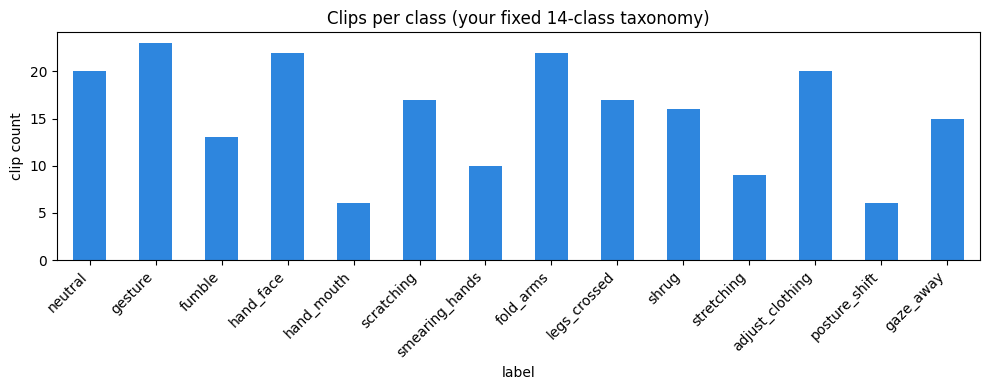

Classes WITH footage (14/14): ['neutral', 'gesture', 'fumble', 'hand_face', 'hand_mouth', 'scratching', 'smearing_hands', 'fold_arms', 'legs_crossed', 'shrug', 'stretching', 'adjust_clothing', 'posture_shift', 'gaze_away']


In [4]:
present = manifest.label.value_counts().reindex(CLASSES, fill_value=0)
missing_classes = present[present == 0].index.tolist()

fig, ax = plt.subplots(figsize=(10, 4))
present.plot(kind="bar", ax=ax, color=["#c0392b" if v == 0 else "#2e86de" for v in present.values])
ax.set_ylabel("clip count")
ax.set_title("Clips per class (your fixed 14-class taxonomy)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print(f"Classes WITH footage ({14 - len(missing_classes)}/14):",
      [c for c in CLASSES if c not in missing_classes])
if missing_classes:
    print(f"\nClasses with ZERO examples ({len(missing_classes)}/14) — cannot be recognized "
          f"until you record footage for them:")
    print(missing_classes)

## 4. Standardize filenames + build the paper-style annotation CSV

The paper's datasets (BBSI / Drive&Act) ship a metadata table (`clip_id, subject_id, class_id, class_name, view, ...`). This cell **builds that table** from the parsed manifest, and writes **standardized-name copies** of your clips in the convention `S{subject}_C{class_id}_{class_name}_T{take}.mp4` into `WORK_DIR/renamed_dataset/` — your original Kaggle input dataset is read-only and is never modified in place.

In [5]:
csv_rows = []
used_names = set()
rename_dir = os.path.join(WORK_DIR, "renamed_dataset")
os.makedirs(rename_dir, exist_ok=True)

for i, r in manifest.iterrows():
    subj_num = int(re.sub(r"\D", "", r.subject_group) or 0)
    ext = os.path.splitext(r.filename)[1].lower() or ".mp4"   # keep the REAL container type
    # Guarantee a UNIQUE standardized name. (Before, two different clips could map to the same
    # name, e.g. "002_gesture.mp4" and "clip_02_gesture.mp4", and the second copy was skipped.)
    take = 1
    while True:
        std_name = f"S{subj_num:03d}_C{r.label_idx + 1:02d}_{r.label}_T{take:02d}{ext}"
        if std_name not in used_names:
            break
        take += 1
    used_names.add(std_name)
    dst = os.path.join(rename_dir, std_name)
    if not os.path.exists(dst):
        shutil.copy2(r.filepath, dst)

    cap = cv2.VideoCapture(r.filepath)
    try:
        rot_meta = int(cap.get(cv2.CAP_PROP_ORIENTATION_META))
    except Exception:
        rot_meta = 0
    n_raw = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = cap.get(cv2.CAP_PROP_FPS)
    w_, h_ = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    cap.release()

    csv_rows.append({
        "clip_id": i,
        "original_filename": r.filename,
        "standardized_filename": std_name,
        "subject_id": r.subject_group,
        "class_id": r.label_idx + 1,
        "class_name": r.label,
        "view": "front_single_view",
        "raw_num_frames": n_raw,
        "raw_fps": round(fps, 2),
        "raw_width": w_,
        "raw_height": h_,
        "rotation_meta": rot_meta,
    })

annotations = pd.DataFrame(csv_rows)
assert annotations.standardized_filename.is_unique
csv_path = os.path.join(WORK_DIR, "annotations.csv")
annotations.to_csv(csv_path, index=False)
print(f"Wrote paper-style annotation CSV -> {csv_path}")
print(f"Wrote {len(annotations)} standardized-name copies -> {rename_dir} "
      f"({len(os.listdir(rename_dir))} files on disk)")
_rot = annotations[annotations.rotation_meta != 0]
print(f"{len(_rot)} clip(s) carry a phone rotation flag (rotation_meta != 0); each is rotated exactly once "
      f"(see Section 5, step 2).")
if len(_rot):
    display(_rot[["clip_id", "original_filename", "rotation_meta", "raw_width", "raw_height"]])
bad_meta = annotations[(annotations.raw_num_frames <= 0) | (annotations.raw_width <= 0)]
if len(bad_meta):
    print(f"WARNING: OpenCV could not read metadata for {len(bad_meta)} clip(s) "
          f"(codec/corruption?) - they will be reported as FAILED in Section 8:")
    display(bad_meta[["clip_id", "original_filename"]])
display(annotations)


Wrote paper-style annotation CSV -> /kaggle/working/annotations.csv
Wrote 216 standardized-name copies -> /kaggle/working/renamed_dataset (216 files on disk)
0 clip(s) carry a phone rotation flag (rotation_meta != 0); each is rotated exactly once (see Section 5, step 2).


,clip_id,original_filename,standardized_filename,subject_id,class_id,class_name,view,raw_num_frames,raw_fps,raw_width,raw_height,rotation_meta
0,0,001_adjusting_cloth.mp4,S001_C12_adjust_clothing_T01.mp4,subj001,12,adjust_clothing,front_single_view,64,16.00,224,224,0
1,1,001_fumble.mp4,S001_C03_fumble_T01.mp4,subj001,3,fumble,front_single_view,65,8.00,224,224,0
2,2,001_neutral.mp4,S001_C01_neutral_T01.mp4,subj001,1,neutral,front_single_view,65,8.00,224,224,0
3,3,001_neutral_64f.mp4,S001_C01_neutral_T02.mp4,subj001,1,neutral,front_single_view,64,16.00,224,224,0
4,4,002_gesture.mp4,S002_C02_gesture_T01.mp4,subj002,2,gesture,front_single_view,49,8.00,736,496,0
...,...,...,...,...,...,...,...,...,...,...,...,...
211,211,stretching4.mp4,S004_C11_stretching_T01.mp4,stretching4,11,stretching,front_single_view,154,29.97,640,360,0
212,212,stretching6.mp4,S006_C11_stretching_T01.mp4,stretching6,11,stretching,front_single_view,291,30.00,1268,714,0
213,213,stretching7.mp4,S007_C11_stretching_T01.mp4,stretching7,11,stretching,front_single_view,231,30.00,1266,706,0
214,214,stretching8.mp4,S008_C11_stretching_T01.mp4,stretching8,11,stretching,front_single_view,309,30.00,1110,560,0


## 5. Core preprocessing — three stages

Your pipeline = **(1) the paper's preprocessing**, **(2) extra steps for real interview recordings**, **(3) the derived streams** (DCT + skeleton, Sections 6–7). This cell group implements stages 1–2; the table says exactly what is reproduced from the paper and what could not be.

### Stage 1 — Paper's preprocessing (§IV-A, §III-B)

| Paper | This notebook |
|---|---|
| Resize every video to 224 × 224 | ✅ step 5 below |
| Fixed 64-frame clips; **drop** clips with < 64 frames | ⚠️ every clip is resampled to exactly 64 frames and **none is dropped** (small dataset) — step 6 |
| Drop clips with occlusion / missing information in any view | ➖ not applicable (one view); replaced by quality flags — step 7 (clips are kept and flagged) |
| 3 synchronized camera views | ➖ not possible: 1 view |
| DCT video from the RGB frames (Fig. 2) | ✅ Section 6 (`DCT_MODE` chooses the variant) |
| 33-joint skeleton: MediaPipe query points → TAPIR tracker | ⚠️ MediaPipe Pose directly (no TAPIR) — Section 7 |
| 2-D `(x, y)` joints; zero-fill joints below a confidence threshold | ✅ Section 7 (threshold `CFG.POSE_MIN_VIS`; the paper gives no value) |
| Positional / Temporal / Spatial streams from the paper's equations | ✅ Section 7 |

*(The paper's Swin features on 32-frame clips and LaViLa on 4 random frames belong to the **model** notebook, not to preprocessing.)*

### Stage 2 — Additional preprocessing for real interviews

Recorded anywhere (phone, laptop webcam, varying light, subject not centred) — none of which the paper's fixed 3-camera studio rig had to deal with:

1. **Video-only decoding.** `cv2.VideoCapture` decodes only the frame stream; the audio track is never read.
2. **Orientation correction.** Phones store a rotation flag instead of rotating pixels. OpenCV ≥ 4.5 already applies that flag while decoding, so this notebook uses OpenCV's rotation when it is on and only rotates by hand on older builds — a clip is **never rotated twice**. Section 4 lists how many clips carry a rotation flag.
3. **Person-centred square crop.** MediaPipe Pose finds the subject (median bounding box over 6 probe frames, so one bad frame cannot wobble the crop); the frame is cropped to a square around them (50 % margin) before resizing. This replaces the paper's fixed camera framing.
4. **Lighting normalization.** CLAHE on the luminance channel (backlight, dim rooms, harsh light).
5. **Resize** to `224 × 224` (paper, §IV-A).
6. **Uniform temporal resampling** to `NUM_FRAMES = 64`. Short clips are stretched by repeating frames at evenly spaced positions (no loop-around jump); long clips are uniformly subsampled; clips over 900 frames are thinned while reading to protect memory.
7. **Occlusion / missing-pose guard.** A frame *fails* when MediaPipe finds no usable pose (no joint above the visibility threshold). Failed frames are zero-filled and recorded per frame (`pose_found`). If more than 40 % of a clip's frames fail, the clip is flagged `low_pose_quality` — it is **kept**, not discarded, so you know its skeleton stream is partly empty. The share of *joints* visible (`vis_rate`) is stored separately.


W0000 00:00:1792001367.230400     103 landmark_projection_calculator.cc:78] Using NORM_RECT without IMAGE_DIMENSIONS is only supported for the square ROI. Provide IMAGE_DIMENSIONS or use PROJECTION_MATRIX.


Preprocessed: 001_adjusting_cloth.mp4 -> (64, 224, 224, 3) uint8
Shape check passed: (NUM_FRAMES, IMG_SIZE, IMG_SIZE, 3) as expected.


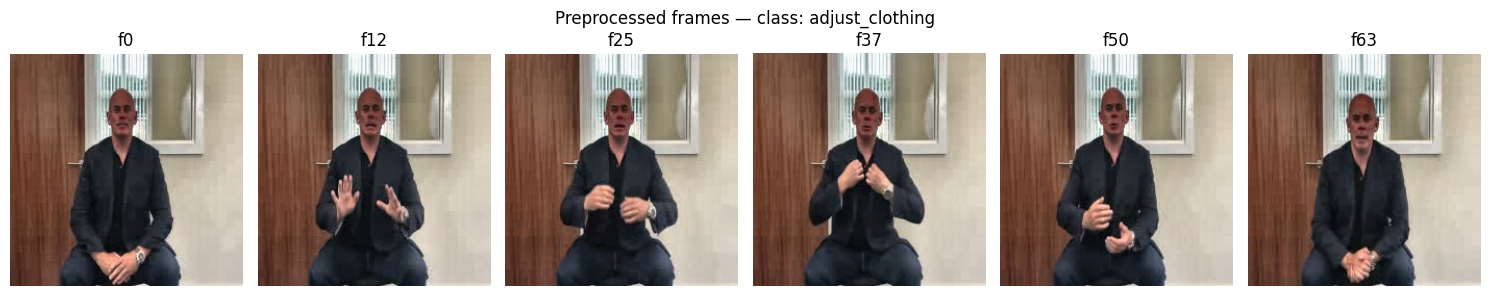

In [6]:
def _fix_rotation(cap, frame):
    """Make sure the person is upright (phone rotation flag) -- exactly once.
    No-op on cameras/webcams that don't set a flag."""
    try:
        # OpenCV >= 4.5 already rotates decoded frames itself (CAP_PROP_ORIENTATION_AUTO == 1) while still
        # reporting the angle in ORIENTATION_META. Rotating again would turn the person sideways / upside-down
        # (verified on 90/180/270-degree clips). So: manual rotation only when OpenCV is NOT doing it.
        if cap.get(cv2.CAP_PROP_ORIENTATION_AUTO) == 1:
            return frame
        angle = int(cap.get(cv2.CAP_PROP_ORIENTATION_META))
    except Exception:
        angle = 0
    if angle == 90:
        return cv2.rotate(frame, cv2.ROTATE_90_CLOCKWISE)
    if angle == 180:
        return cv2.rotate(frame, cv2.ROTATE_180)
    if angle == 270:
        return cv2.rotate(frame, cv2.ROTATE_90_COUNTERCLOCKWISE)
    return frame

def _clahe_rgb(frame_rgb):
    lab = cv2.cvtColor(frame_rgb, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    l = clahe.apply(l)
    lab = cv2.merge((l, a, b))
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

def _read_raw_frames(path):
    cap = cv2.VideoCapture(path)  # decodes the video stream only; audio is never touched
    if not cap.isOpened():
        raise RuntimeError(f"OpenCV could not open video: {path}")
    # Memory guard: a clip with thousands of HD frames can exhaust RAM and kill the kernel (which
    # would also kill the whole 176-clip run). Above MAX_RAW_FRAMES we keep every k-th frame while
    # reading; the result is resampled to NUM_FRAMES afterwards anyway, so it stays uniform.
    # Clips at or below MAX_RAW_FRAMES (all the ones you've seen so far) are untouched.
    MAX_RAW_FRAMES = 900
    n_hdr = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    stride = max(1, math.ceil(n_hdr / MAX_RAW_FRAMES)) if n_hdr > 0 else 1
    frames, idx = [], 0
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        if idx % stride == 0:
            frame = _fix_rotation(cap, frame)
            frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        idx += 1
    cap.release()
    return frames

def _estimate_person_bbox(frames, pose_detector, n_probe=6):
    idxs = np.linspace(0, len(frames) - 1, min(n_probe, len(frames))).astype(int)
    boxes = []
    for i in idxs:
        h, w, _ = frames[i].shape
        res = pose_detector.process(frames[i])
        if res.pose_landmarks:
            xs = [lm.x for lm in res.pose_landmarks.landmark if lm.visibility > 0.3]
            ys = [lm.y for lm in res.pose_landmarks.landmark if lm.visibility > 0.3]
            if xs and ys:
                boxes.append((min(xs) * w, min(ys) * h, max(xs) * w, max(ys) * h))
    if not boxes:
        return None
    boxes = np.array(boxes)
    return tuple(np.median(boxes, axis=0))  # (x0, y0, x1, y1) -- robust to a single bad probe frame

def _square_crop(frame, bbox, margin=0.5):
    h, w, _ = frame.shape
    if bbox is None:
        s = min(h, w)
        y0, x0 = (h - s) // 2, (w - s) // 2
        return frame[y0:y0 + s, x0:x0 + s]
    x0, y0, x1, y1 = bbox
    cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
    side = max(x1 - x0, y1 - y0) * (1 + margin)
    side = min(side, min(h, w))
    side = max(side, 8.0)  # never collapse to a 0px crop on a degenerate bbox
    hx0 = int(np.clip(cx - side / 2, 0, w - side))
    hy0 = int(np.clip(cy - side / 2, 0, h - side))
    side = int(side)
    return frame[hy0:hy0 + side, hx0:hx0 + side]

def _resample_temporal(frames, n_out):
    n_in = len(frames)
    if n_in == n_out:
        return frames
    idxs = np.linspace(0, n_in - 1, n_out).round().astype(int)
    return [frames[i] for i in idxs]

def preprocess_video(path, img_size=CFG.IMG_SIZE, n_frames=CFG.NUM_FRAMES):
    """Video-only decode -> orientation fix -> person-centred square crop -> CLAHE ->
    resize -> temporal resample. Returns uint8 array (T, H, W, 3) in RGB."""
    raw = _read_raw_frames(path)
    if len(raw) == 0:
        raise RuntimeError(f"No frames decoded from {path} (corrupt file or unsupported codec).")
    bbox = _estimate_person_bbox(raw, POSE_DETECTOR)  # shared model instance, no per-clip reload
    cropped = [_square_crop(f, bbox) for f in raw]
    normed = [_clahe_rgb(f) for f in cropped]
    resized = [cv2.resize(f, (img_size, img_size), interpolation=cv2.INTER_AREA) for f in normed]
    sampled = _resample_temporal(resized, n_frames)
    return np.stack(sampled, axis=0).astype(np.uint8)

# ---- sanity check on one real clip from your dataset ----
_sample_path = manifest.filepath.iloc[0]
_sample_frames = preprocess_video(_sample_path)
print("Preprocessed:", manifest.filename.iloc[0], "->", _sample_frames.shape, _sample_frames.dtype)
assert _sample_frames.shape == (CFG.NUM_FRAMES, CFG.IMG_SIZE, CFG.IMG_SIZE, 3)
print("Shape check passed: (NUM_FRAMES, IMG_SIZE, IMG_SIZE, 3) as expected.")

fig, axes = plt.subplots(1, 6, figsize=(15, 3))
for k, ax in enumerate(axes):
    idx = int(k * (len(_sample_frames) - 1) / 5)
    ax.imshow(_sample_frames[idx])
    ax.set_title(f"f{idx}")
    ax.axis("off")
plt.suptitle(f"Preprocessed frames — class: {manifest.label.iloc[0]}")
plt.tight_layout()
plt.show()

## 6. DCT stream (§III-B1, Fig. 2 of the paper)

Per the paper: *"we apply DCT on RGB frames to generate a DCT video."* We run a 2D DCT per channel per frame, take the log-magnitude (high-frequency energy = edges/texture — exactly the property the paper exploits for hand/finger motion), and rescale to a viewable/CNN-consumable `uint8` image, producing a DCT "video" with the same shape as the RGB stream.

`DCT_MODE` (top of the next cell) chooses `"full_frame"` (as in your earlier runs) or `"block"` (8×8 block DCT that keeps the picture's spatial layout).

DCT_MODE = 'full_frame'
DCT stream: (64, 224, 224, 3) uint8 (value range 0-255)


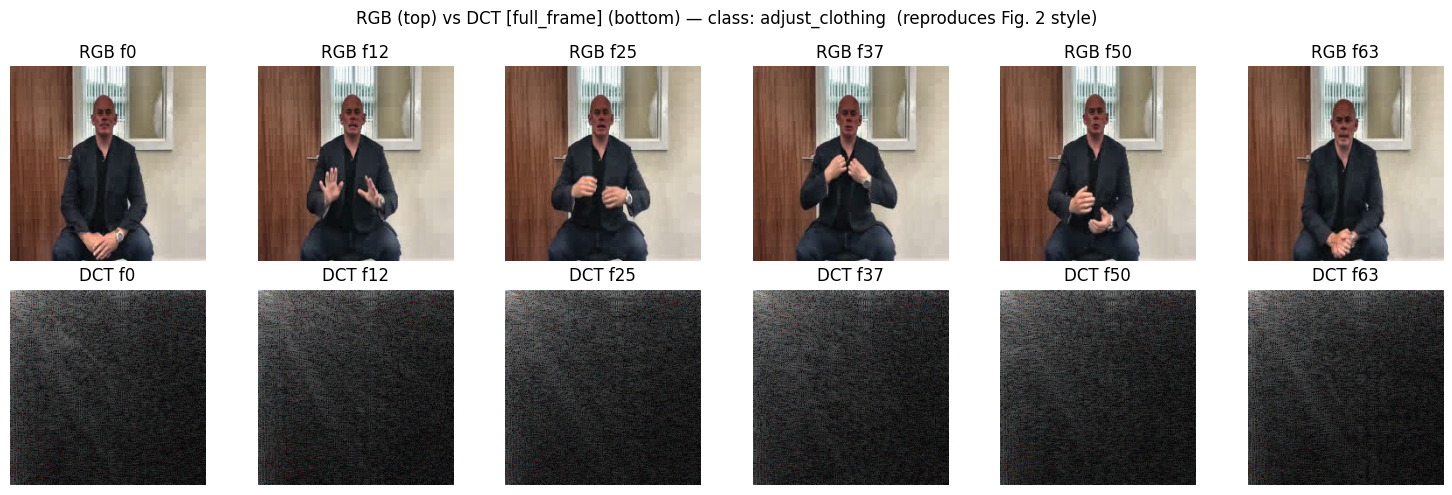

In [7]:
# DCT_MODE:
#   "full_frame" = one DCT over the whole 224x224 frame (what your earlier runs used; keeps results comparable)
#   "block"      = 8x8 block DCT (JPEG-style): every block's coefficients stay at that block's position, so the
#                  picture keeps its spatial layout, which Swin needs. Try this if DCT-only accuracy stays near chance.
DCT_MODE = "full_frame"

def _frame_to_dct_full(frame_rgb):
    """Per-channel 2D DCT over the whole frame -> log-magnitude, rescaled to uint8."""
    out = np.zeros_like(frame_rgb, dtype=np.float32)
    for c in range(3):
        ch = frame_rgb[:, :, c].astype(np.float32)
        d = cv2.dct(ch)
        mag = np.log1p(np.abs(d))
        rng = mag.max() - mag.min()
        mag = (mag - mag.min()) / (rng + 1e-8) * 255.0
        out[:, :, c] = mag
    return out.astype(np.uint8)

def _dct_matrix(n=8):
    k = np.arange(n)[:, None]; i = np.arange(n)[None, :]
    D = np.sqrt(2.0 / n) * np.cos((2 * i + 1) * k * np.pi / (2 * n))
    D[0, :] = np.sqrt(1.0 / n)
    return D.astype(np.float32)          # orthonormal DCT-II, identical to cv2.dct on an 8x8 block

_D8 = _dct_matrix(8)

def _frame_to_dct_block(frame_rgb, block=8):
    """8x8 block DCT (vectorised): log-magnitude with a fixed scale, so frames stay comparable."""
    h, w, _ = frame_rgb.shape
    assert h % block == 0 and w % block == 0, "frame size must be a multiple of 8"
    x = (frame_rgb.astype(np.float32) - 128.0).reshape(h // block, block, w // block, block, 3)
    out = np.einsum("ij,hjwkc,lk->hiwlc", _D8, x, _D8, optimize=True).reshape(h, w, 3)
    mag = np.log1p(np.abs(out))
    return np.clip(mag / np.log1p(1024.0) * 255.0, 0, 255).astype(np.uint8)

def frame_to_dct(frame_rgb):
    """Mirrors Fig. 2 of the paper. Mode chosen by DCT_MODE."""
    if DCT_MODE == "block":
        return _frame_to_dct_block(frame_rgb)
    return _frame_to_dct_full(frame_rgb)

def video_to_dct(frames):
    return np.stack([frame_to_dct(f) for f in frames], axis=0)

print(f"DCT_MODE = {DCT_MODE!r}")
_sample_dct = video_to_dct(_sample_frames)
assert _sample_dct.shape == _sample_frames.shape
print("DCT stream:", _sample_dct.shape, _sample_dct.dtype,
      f"(value range {_sample_dct.min()}-{_sample_dct.max()})")

fig, axes = plt.subplots(2, 6, figsize=(15, 5))
for k in range(6):
    idx = int(k * (len(_sample_frames) - 1) / 5)
    axes[0, k].imshow(_sample_frames[idx]); axes[0, k].set_title(f"RGB f{idx}"); axes[0, k].axis("off")
    axes[1, k].imshow(_sample_dct[idx]);    axes[1, k].set_title(f"DCT f{idx}"); axes[1, k].axis("off")
plt.suptitle(f"RGB (top) vs DCT [{DCT_MODE}] (bottom) — class: {manifest.label.iloc[0]}  (reproduces Fig. 2 style)")
plt.tight_layout()
plt.show()


## 7. Three-stream skeleton (§III-B4, Fig. 3 of the paper)

The paper tracks 33 body joints with TAPIR, seeded by MediaPipe Pose landmarks. For a single-view, real-time interview setting we use **MediaPipe Pose directly** as the per-frame joint tracker (33 landmarks, 2D `(x, y)` — the paper's TAPIR features were 2D too), which is the practical real-time equivalent without standing up the heavier TAPIR matching+refinement stage. Low-confidence joints (`visibility < CFG.POSE_MIN_VIS`) are zero-filled, exactly as the paper does for occluded points.

`MASK_INVALID_IN_T_S` (top of the next cell) controls one side effect of zero-filling: a zero-filled joint makes the Spatial value `mid-hip − 0` (a large fake vector) and makes the Temporal value jump by the joint's full coordinate when it appears/disappears. `False` (default) = literally the paper's recipe, comparable with your earlier runs; `True` = those fake values are set to 0 instead (only valid joint pairs contribute).

Three streams are built exactly per the paper's equations (§III-B4):
- **Positional (P):** raw `(x, y)` per joint per frame.
- **Temporal (T):** frame-to-frame joint displacement, `T = J_i^t − J_i^{t+1}`.
- **Spatial (S):** distance vector from the mid-hip reference joint to every other joint (excludes the 2 hip joints used as the reference, hence `N−2`).


Positional (64, 33, 2) | Temporal (63, 33, 2) | Spatial (64, 31, 2) | mean joint visibility: 85.6% | frames with a usable pose: 100.0%


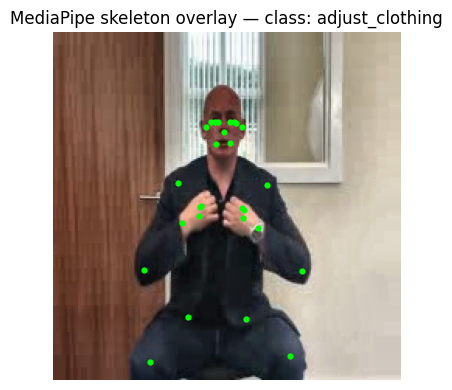

In [8]:
# MediaPipe Pose landmark indices (identical in the legacy and the Tasks API): 23 = left hip, 24 = right hip
LEFT_HIP, RIGHT_HIP = 23, 24
N_JOINTS = 33
MASK_INVALID_IN_T_S = False   # see the markdown above; False = paper-literal (default)

def extract_skeleton_sequence(frames, min_vis=CFG.POSE_MIN_VIS):
    """Returns positions (F, 33, 2) float32 and a visibility mask (F, 33) bool."""
    F_ = len(frames)
    pos = np.zeros((F_, N_JOINTS, 2), dtype=np.float32)
    vis_mask = np.zeros((F_, N_JOINTS), dtype=bool)
    for t, frame in enumerate(frames):
        h, w, _ = frame.shape
        res = POSE_DETECTOR.process(frame)  # shared model instance, no per-clip reload
        if res.pose_landmarks is None:
            continue
        for j, lm in enumerate(res.pose_landmarks.landmark):
            if lm.visibility >= min_vis:
                pos[t, j] = [lm.x * w, lm.y * h]
                vis_mask[t, j] = True
    return pos, vis_mask

def build_three_streams(pos, vis=None):
    """pos: (F, 33, 2) -> Positional P, Temporal T, Spatial S (paper §III-B4).
    vis (F, 33) bool is only used when MASK_INVALID_IN_T_S is True."""
    F_, N_, _ = pos.shape
    P = pos.copy()                                               # (F, N, 2)
    T = pos[:-1] - pos[1:]                                        # (F-1, N, 2)
    mid_hip = (pos[:, LEFT_HIP] + pos[:, RIGHT_HIP]) / 2.0         # (F, 2)
    keep = [j for j in range(N_) if j not in (LEFT_HIP, RIGHT_HIP)]
    S = mid_hip[:, None, :] - pos[:, keep, :]                      # (F, N-2, 2)
    if MASK_INVALID_IN_T_S and vis is not None:
        T[~(vis[:-1] & vis[1:])] = 0.0                              # joint missing in either frame
        hips_ok = vis[:, LEFT_HIP] & vis[:, RIGHT_HIP]
        S[~(vis[:, keep] & hips_ok[:, None])] = 0.0                 # joint or mid-hip reference missing
    return P.astype(np.float32), T.astype(np.float32), S.astype(np.float32)

_sample_pos, _sample_vis = extract_skeleton_sequence(_sample_frames)
_P, _T, _S = build_three_streams(_sample_pos, _sample_vis)
assert _P.shape == (CFG.NUM_FRAMES, N_JOINTS, 2)
assert _T.shape == (CFG.NUM_FRAMES - 1, N_JOINTS, 2)
assert _S.shape == (CFG.NUM_FRAMES, N_JOINTS - 2, 2)
print("Positional", _P.shape, "| Temporal", _T.shape, "| Spatial", _S.shape,
      f"| mean joint visibility: {_sample_vis.mean():.1%} "
      f"| frames with a usable pose: {_sample_vis.any(axis=1).mean():.1%}")

fig, ax = plt.subplots(figsize=(4, 4))
mid_frame = len(_sample_frames) // 2
ax.imshow(_sample_frames[mid_frame])
pts, valid = _sample_pos[mid_frame], _sample_vis[mid_frame]
if valid.any():
    ax.scatter(pts[valid, 0], pts[valid, 1], c="lime", s=12)
else:
    ax.text(0.5, 0.5, "no joints above\nvisibility threshold\non this frame",
            ha="center", va="center", transform=ax.transAxes, color="red", fontsize=9)
ax.set_title(f"MediaPipe skeleton overlay — class: {manifest.label.iloc[0]}")
ax.axis("off")
plt.tight_layout()
plt.show()

## 8. Run the full preprocessing pipeline over every clip (with per-clip output)

Every clip is preprocessed once; its RGB stream, DCT stream, and three skeleton streams (P, T, S) are cached to disk as one `.pt` (PyTorch) file per clip, so a later modeling notebook never has to re-decode video. A quality flag (`low_pose_quality`: MediaPipe found a usable pose on fewer than 60 % of the frames, i.e. more than 40 % failed) is logged per clip, together with the share of joints visible — this loop is safe to re-run: already-cached clips are skipped, so interrupting it costs nothing.

*(If you hit Kaggle's `Failed to execute 'json' on 'Response'` error when committing: that's the platform's commit step timing out or returning a truncated response on a long-running/high-output kernel, not a bug in this code. Section 0 above already removes the biggest cause of that — repeated MediaPipe model reloads flooding the log — but if it still happens, try Quick Save first, then Save & Run All again; ensure the notebook's Internet toggle is ON before committing; or commit once with a smaller `CFG.NUM_FRAMES` to shorten the run.)*

In [9]:
import gc, json, traceback

CACHE_DIR = os.path.join(WORK_DIR, "cache")
os.makedirs(CACHE_DIR, exist_ok=True)

def cache_path_for(clip_id):
    return os.path.join(CACHE_DIR, f"clip_{clip_id:03d}.pt")

# --- stale-cache guard ----------------------------------------------------------------------
# Resume-skipping is keyed by clip_id only, so a cache left over from a DIFFERENT dataset (other clip order)
# would be silently reused for the wrong videos. Every cached clip therefore records which source file,
# size, class and DCT mode produced it; a mismatch (or a missing record) means "recompute this one".
SIG_PATH = os.path.join(CACHE_DIR, "_signature.json")
try:
    with open(SIG_PATH) as _fh:
        SIGS = json.load(_fh)
except Exception:
    SIGS = {}

def clip_signature(r):
    src = manifest.iloc[r.clip_id].filepath
    return f"{r.original_filename}|{os.path.getsize(src)}|{r.class_name}|dct={DCT_MODE}|mask={MASK_INVALID_IN_T_S}|v2"

def save_sigs():
    tmp = SIG_PATH + ".tmp"
    with open(tmp, "w") as fh:
        json.dump(SIGS, fh)
    os.replace(tmp, SIG_PATH)

_stale = 0
for _, r in annotations.iterrows():
    cp = cache_path_for(r.clip_id)
    if os.path.exists(cp) and SIGS.get(str(int(r.clip_id))) != clip_signature(r):
        os.remove(cp)
        _stale += 1
if _stale:
    print(f"Removed {_stale} stale cached clip(s) that did not match the current dataset -> they will be recomputed.")
_valid_ids = set(int(x) for x in annotations.clip_id)
_orphans = 0
for _p in glob.glob(os.path.join(CACHE_DIR, "*.pt")):
    _m = re.search(r"clip_(\d+)\.pt$", os.path.basename(_p))
    if not _m or int(_m.group(1)) not in _valid_ids:
        os.remove(_p)
        _orphans += 1
for _k in [k for k in SIGS if int(k) not in _valid_ids]:
    del SIGS[_k]
if _orphans:
    print(f"Removed {_orphans} leftover cache file(s) that belong to no clip of the current dataset.")

quality_log, failed_log = [], []
n_cached_now = 0
for i, r in annotations.iterrows():
    cpath = cache_path_for(r.clip_id)
    if os.path.exists(cpath):
        continue
    src_row = manifest.iloc[r.clip_id]
    # One bad/corrupt clip must NEVER stop the other 139: catch, log, keep going.
    try:
        frames = preprocess_video(src_row.filepath)
        dct_frames = video_to_dct(frames)
        pos, vis = extract_skeleton_sequence(frames)
        P, T, S = build_three_streams(pos, vis)
        vis_rate = float(vis.mean())                       # share of (frame, joint) pairs that were visible
        pose_found = vis.any(axis=1)                       # (64,) frame had a usable pose
        pose_frame_rate = float(pose_found.mean())
        low_quality = pose_frame_rate < 0.6                # >40 % of frames failed (Section 5, step 7)
        # Saved as a .pt file (torch.save on a plain dict) so the modeling notebook can
        # `torch.load(...)` this directly with no numpy->tensor conversion step.
        torch.save({
            "frames": torch.from_numpy(frames),               # uint8  (64, 224, 224, 3)
            "dct_frames": torch.from_numpy(dct_frames),        # uint8  (64, 224, 224, 3)
            "P": torch.from_numpy(P),                          # float32 (64, 33, 2)
            "T": torch.from_numpy(T),                          # float32 (63, 33, 2)
            "S": torch.from_numpy(S),                          # float32 (64, 31, 2)
            "label": torch.tensor(r.class_id - 1, dtype=torch.long),  # 0-indexed class id
            "vis_rate": vis_rate,                              # plain float: share of joints visible
            "pose_frame_rate": pose_frame_rate,                # plain float: share of frames with a usable pose
            "pose_found": torch.from_numpy(pose_found),        # bool (64,) per-frame detection record
        }, cpath)
    except Exception as e:
        failed_log.append({"clip_id": r.clip_id, "filename": r.original_filename,
                           "error": f"{type(e).__name__}: {e}"})
        if os.path.exists(cpath):          # never leave a half-written file that looks "done"
            os.remove(cpath)
        print(f"[{i + 1:3d}/{len(annotations)}] {r.original_filename:30s} -> FAILED  {type(e).__name__}: {e}")
        continue
    SIGS[str(int(r.clip_id))] = clip_signature(r)
    save_sigs()
    quality_log.append({
        "clip_id": r.clip_id, "filename": r.original_filename, "class": r.class_name,
        "pose_visibility_rate": round(vis_rate, 3), "pose_frame_rate": round(pose_frame_rate, 3),
        "low_pose_quality": low_quality,
    })
    n_cached_now += 1
    flag = "  <-- LOW POSE QUALITY" if low_quality else ""
    print(f"[{i + 1:3d}/{len(annotations)}] {r.original_filename:30s} -> class={r.class_name:16s} "
          f"joints_vis={vis_rate:5.1%} frames_ok={pose_frame_rate:5.1%}  cached -> {os.path.basename(cpath)}{flag}")
    del frames, dct_frames, pos, vis, P, T, S
    gc.collect()

quality_df = pd.DataFrame(quality_log)
print(f"\nNewly cached this run: {n_cached_now} "
      f"(clips already cached from a previous run were skipped, not reprocessed)")

if len(quality_df):
    bad = quality_df[quality_df.low_pose_quality]
    if len(bad):
        print(f"\n{len(bad)} clip(s) flagged low_pose_quality "
              f"(a usable pose in <60% of frames) — their skeleton stream is partly zero-filled:")
        display(bad)
    else:
        print("\nAll newly processed clips had good pose tracking (>=60% of frames).")

if failed_log:
    print(f"\n{len(failed_log)} clip(s) FAILED to preprocess (fix/re-encode them, then re-run this cell - "
          f"it only redoes the missing ones):")
    display(pd.DataFrame(failed_log))

total_cached = len(glob.glob(os.path.join(CACHE_DIR, "*.pt")))
print(f"\nTotal cached feature files: {total_cached} / {len(annotations)} clips")
if total_cached == len(annotations):
    print(f"ALL {len(annotations)} CLIPS PREPROCESSED SUCCESSFULLY.")
else:
    missing_ids = sorted(set(annotations.clip_id) - {int(os.path.basename(p)[5:8]) for p in glob.glob(os.path.join(CACHE_DIR, '*.pt'))})
    print("Missing clip_ids:", missing_ids)

# ---- reload one cached file to prove the cache round-trips correctly ----
_first_cached = sorted(glob.glob(os.path.join(CACHE_DIR, "*.pt")))[0]
_check = torch.load(_first_cached, weights_only=False)
print("\nSanity check — reloaded", os.path.basename(_first_cached), "contains:")
for k in ["frames", "dct_frames", "P", "T", "S", "label"]:
    v = _check[k]
    print(f"  {k:12s} shape={tuple(v.shape)}  dtype={v.dtype}")
print(f"  {'vis_rate':12s} = {_check['vis_rate']:.3f}")


[  1/216] 001_adjusting_cloth.mp4        -> class=adjust_clothing  joints_vis=85.6% frames_ok=100.0%  cached -> clip_000.pt
[  2/216] 001_fumble.mp4                 -> class=fumble           joints_vis=76.3% frames_ok=100.0%  cached -> clip_001.pt
[  3/216] 001_neutral.mp4                -> class=neutral          joints_vis=87.2% frames_ok=100.0%  cached -> clip_002.pt
[  4/216] 001_neutral_64f.mp4            -> class=neutral          joints_vis=70.2% frames_ok=100.0%  cached -> clip_003.pt
[  5/216] 002_gesture.mp4                -> class=gesture          joints_vis=73.6% frames_ok=100.0%  cached -> clip_004.pt
[  6/216] 002_gesture_64f.mp4            -> class=gesture          joints_vis=69.8% frames_ok=100.0%  cached -> clip_005.pt
[  7/216] 002_neutral.mp4                -> class=neutral          joints_vis=83.3% frames_ok=100.0%  cached -> clip_006.pt
[  8/216] 003_gesture.mp4                -> class=gesture          joints_vis=84.8% frames_ok=100.0%  cached -> clip_007.pt
[  9/216

,clip_id,filename,class,pose_visibility_rate,pose_frame_rate,low_pose_quality
32,32,adjust_clothing13.mp4,adjust_clothing,0.357,0.578,True
73,73,fumble10.mp4,fumble,0.043,0.094,True
96,96,gesture.mp4,gesture,0.126,0.188,True
142,142,legs_crossed3.mp4,legs_crossed,0.223,0.297,True



Total cached feature files: 216 / 216 clips
ALL 216 CLIPS PREPROCESSED SUCCESSFULLY.

Sanity check — reloaded clip_000.pt contains:
  frames       shape=(64, 224, 224, 3)  dtype=torch.uint8
  dct_frames   shape=(64, 224, 224, 3)  dtype=torch.uint8
  P            shape=(64, 33, 2)  dtype=torch.float32
  T            shape=(63, 33, 2)  dtype=torch.float32
  S            shape=(64, 31, 2)  dtype=torch.float32
  label        shape=()  dtype=torch.int64
  vis_rate     = 0.856


## 9. Dataset-wide preprocessing quality summary

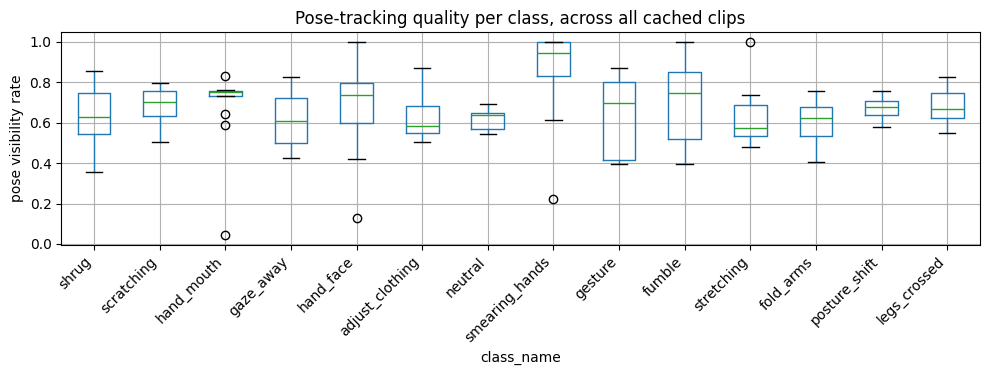

Overall mean pose visibility across the dataset: 66.7%
Overall share of frames with a usable pose: 98.3%
Clips with a usable pose in <60% of frames (low_pose_quality): 4 / 216
Clips with <60% of joints visible (e.g. legs out of frame): 71 / 216


In [10]:
all_quality = []
for _, r in annotations.iterrows():
    if not os.path.exists(cache_path_for(r.clip_id)):
        continue   # clip failed in Section 8 (listed there)
    d = torch.load(cache_path_for(r.clip_id), weights_only=False)
    all_quality.append({
        "clip_id": r.clip_id, "class_name": r.class_name,
        "pose_visibility_rate": float(d["vis_rate"]),
        "pose_frame_rate": float(d.get("pose_frame_rate", float("nan"))),
    })
qdf = pd.DataFrame(all_quality)

fig, ax = plt.subplots(figsize=(10, 4))
order = qdf.groupby("class_name")["pose_visibility_rate"].mean().sort_values().index
qdf.boxplot(column="pose_visibility_rate", by="class_name", ax=ax,
            positions=range(len(order)))
ax.set_xticklabels(order, rotation=45, ha="right")
ax.set_ylabel("pose visibility rate")
ax.set_title("Pose-tracking quality per class, across all cached clips")
plt.suptitle("")
plt.tight_layout()
plt.show()

print(f"Overall mean pose visibility across the dataset: {qdf.pose_visibility_rate.mean():.1%}")
print(f"Overall share of frames with a usable pose: {qdf.pose_frame_rate.mean():.1%}")
print(f"Clips with a usable pose in <60% of frames (low_pose_quality): {(qdf.pose_frame_rate < 0.6).sum()} / {len(qdf)}")
print(f"Clips with <60% of joints visible (e.g. legs out of frame): {(qdf.pose_visibility_rate < 0.6).sum()} / {len(qdf)}")

## 10. What this notebook produced

All under `WORK_DIR` (`/kaggle/working` on Kaggle):

- **`manifest.csv`** — every clip with its parsed class + subject group.
- **`annotations.csv`** — the paper-style metadata table (`clip_id, subject_id, class_id, class_name, view, raw_num_frames, raw_fps, ...`).
- **`renamed_dataset/`** — standardized-name copies of your clips (`S{subject}_C{class}_{name}_T{take}.mp4`); your original Kaggle input is untouched.
- **`cache/clip_XXX.pt`** — one **PyTorch** file per clip, `torch.load(...)`-able directly, containing everything downstream modeling needs:
  - `frames` — preprocessed RGB video tensor, `(64, 224, 224, 3)` uint8
  - `dct_frames` — DCT stream tensor, same shape
  - `P`, `T`, `S` — the three skeleton stream tensors
  - `label` — integer class id tensor (0-indexed, matches `CLASSES`)
  - `vis_rate` — pose-tracking quality flag (plain float, for filtering/diagnostics)
- **`preprocessed_dataset.zip`** — `annotations.csv`, `manifest.csv`, and every `cache/*.pt` file, zipped together for a single download (built in the final cell below).

**On Kaggle, don't forget to commit/save the notebook version** (or download `WORK_DIR`) before your session ends — `/kaggle/working` is wiped between sessions unless the notebook is saved with output, or you re-upload `cache/` (or `preprocessed_dataset.zip`) as a new Kaggle dataset input for the modeling notebook.

**Next step (separate notebook, not this one):** feed `annotations.csv` + `cache/*.pt` into the RGB/DCT backbone feature extraction, the three-stream skeleton transformer, and the attention-fusion classifier (§III-C of the paper).


In [11]:
# 11. Zip annotations.csv + manifest.csv + every cache/*.pt into one downloadable archive
# (writes straight into the zip -- no temporary copy of all .pt files, which would double
# disk usage with 176 clips; .pt tensors are already dense so ZIP_STORED is fast)
import zipfile
zip_path = os.path.join(WORK_DIR, "preprocessed_dataset.zip")
if os.path.exists(zip_path):
    os.remove(zip_path)
pt_files = sorted(glob.glob(os.path.join(CACHE_DIR, "*.pt")))
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_STORED, allowZip64=True) as zf:
    zf.write(os.path.join(WORK_DIR, "annotations.csv"), "annotations.csv")
    zf.write(os.path.join(WORK_DIR, "manifest.csv"), "manifest.csv")
    for f in pt_files:
        zf.write(f, os.path.join("cache", os.path.basename(f)))
print(f"Zipped {len(pt_files)} .pt file(s) + annotations.csv + manifest.csv")
print(f"-> {zip_path}  ({os.path.getsize(zip_path) / 1e6:.1f} MB)")
print("\nOn Kaggle: this file appears under the notebook's Output tab once the version "
      "is committed (Save & Run All) -- download it from there, or re-upload it as a "
      "new Kaggle dataset input for the modeling notebook.")


Zipped 216 .pt file(s) + annotations.csv + manifest.csv
-> /kaggle/working/preprocessed_dataset.zip  (4173.3 MB)

On Kaggle: this file appears under the notebook's Output tab once the version is committed (Save & Run All) -- download it from there, or re-upload it as a new Kaggle dataset input for the modeling notebook.
